# Лабораторная работа №6: Построение и оценка VLM-пайплайна

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Запустить quantized VLM 2–4B.
- Создать evaluation JSONL.
- Сравнить prompts, resolution и decoding; разметить ошибки.


## Теоретическая часть

VLM связывает visual encoder, projector и language model. Оценка должна разделять captioning, VQA, OCR и structured extraction, фиксировать prompt, decoding и ошибки: hallucination, counting, spatial relations.

![Пример изображения для Visual Question Answering](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/vqa-example.png)


VLM расшифровывается как Vision-Language Model, то есть модель, работающая одновременно с изображениями и текстом. На вход она получает пару — картинку и текстовый запрос, а на выходе выдаёт текст. Внутри это не единая сеть, а конструкция из трёх частей, соединённых последовательно, и понимание того, как именно они соединены, напрямую влияет на то, какие метрики имеют смысл, а какие нет.

Первая часть — visual encoder, визуальный энкодер. Его задача — превратить картинку в набор числовых векторов, с которыми дальше сможет работать языковая модель. Изображение нарезается на квадратные куски — патчи, обычно 14 на 14 или 16 на 16 пикселей. Каждый патч превращается в вектор, к нему добавляется информация о том, где этот патч находился на картинке (это называется позиционным кодированием), и всё это прогоняется через несколько слоёв self-attention. Self-attention — это механизм, при котором каждый патч «смотрит» на все остальные патчи и обновляет своё представление с учётом контекста. В результате получается последовательность векторов, которую называют visual tokens, визуальными токенами.

Вторая часть — projector, проектор. Проектор обычно представляет собой либо двухслойный MLP, то есть небольшую нейросеть с одним скрытым слоем, либо так называемый Q-Former — маленький трансформер, который умеет сжимать много визуальных токенов в фиксированное число «query-токенов». Q-Former полезен, когда визуальных токенов очень много, а бюджет языковой модели ограничен. Проектор — узкое место: если он слабый, детали изображения теряются ещё до того, как попадут в языковую модель, и никакое увеличение разрешения это не спасёт.

Третья часть — language model, языковая модель. Это обычный decoder-only трансформер, как GPT или Qwen. Он получает на вход последовательность, состоящую из визуальных токенов, специальных токенов-разделителей вроде vision_start и vision_end, и текстовых токенов промпта, и начинает авторегрессивно генерировать ответ — токен за токеном, где каждый следующий токен зависит от всех предыдущих. При генерации используется KV-cache: ключи и значения внимания для всех уже обработанных токенов сохраняются, чтобы не пересчитывать их заново.

У открытого ответа бесконечно много правильных формулировок: «чёрная птица на стене», «грач на парапете», «a black bird on a wall» — все верны, но точное совпадение строк между ними невозможно. Разные задачи требуют разных метрик: для VQA и OCR — короткие детерминированные ответы, для captioning — ручная оценка, для structured — проверка JSON-полей. И ошибки бывают разного типа: неправильный объект, правильный ответ в неверном формате, отказ, галлюцинация. Exact match видит все эти случаи одинаково — как ноль.

**Exact Match (EM)** — точное совпадение после нормализации:

$$
\text{EM}(p, r) = \begin{cases} 1, & \text{norm}(p) = \text{norm}(r) \\ 0, & \text{иначе} \end{cases}
$$

Нормализация приводит к нижнему регистру, убирает пунктуацию, артикли и лишние пробелы. EM хорош для VQA/OCR, бесполезен для captioning.

**Hallucination rate** — доля утверждений в ответе, не подтверждённых изображением:

$$
H = \frac{N_{\text{unsupported}}}{N_{\text{claims}}}
$$

Например, ответ «птица на стене, вокруг деревья и небо» — три утверждения. Если деревья и небо есть, а птицы нет, то $H = 1/3 \approx 0.33$. Считается вручную или через NLI-модель.

**Judge rubric** — формализованная шкала (обычно 0–2), по которой эксперт или LLM оценивает ответ. Пример для captioning: 0 — описан не тот объект, 1 — объект верный, но детали неточны, 2 — описание точно.

## Практическое задание

1. Запустить quantized VLM 2–4B.
2. Создать evaluation JSONL.
3. Сравнить prompts, resolution и decoding; разметить ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** VLM 4B NF4 inference, одно изображение.
- **Ограничение данных:** 20 evaluation examples: 5 на каждый из четырёх типов задач.
- **Fallback:** VLM 2B NF4 с тем же API.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и инференсу; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение.
# ВАЖНО: PYTORCH_CUDA_ALLOC_CONF надо выставить ДО import torch — иначе не подхватится.
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True,max_split_size_mb:128"

from pathlib import Path
import json, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"

_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next(
    (c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\SuperXoma\\Downloads\\SOTA\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Оценочный набор с происхождением

*Вес: 1 балл.*

**Постановка.** Используйте PixMo-Cap, PixMo-AskModelAnything, PixMo-Docs и PixMo-Count с опубликованными эталонами и сохраняйте происхождение каждой записи; локальных файлов от студента не требуется.

Выполните следующие действия:
1. Загрузите открытые изображения и опубликованные ответы через `open_eval_data.load_open_eval`; сохраните URL, split, индекс записи и сведения о лицензировании.
2. Проверьте размер набора и наличие captioning, VQA, OCR и structured extraction.

**Результат.** eval.jsonl с проверяемыми примерами и абсолютными либо существующими путями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Датасет **PixMo** (Pixels for Molmo) — это набор данных, созданный Allen Institute for AI (Ai2) для обучения семейства VLM-моделей **Molmo**.

**PixMo-Cap** — подмножество для **captioning**. Слово captioning переводится как «подписывание», то есть задача сгенерировать текстовое описание изображения.

**PixMo-AskModelAnything** — подмножество для **VQA**. Аббревиатура VQA расшифровывается как Visual Question Answering, то есть «визуальный вопрос-ответ». Это задача: дано изображение и вопрос к нему, нужно дать короткий ответ.

**PixMo-Docs** — подмножество для **OCR**. Аббревиатура OCR расшифровывается как Optical Character Recognition, то есть «оптическое распознавание символов». Это задача прочитать текст с изображения и ответить на вопрос по нему.

**PixMo-Count** — подмножество для **structured extraction**. Словосочетание structured extraction переводится как «структурированное извлечение», то есть задача вернуть ответ в жёстко заданном формате (у нас — JSON с полями label и count).

Языковая модель **Qwen2-VL-2B-Instruct**

In [3]:
# Реализуйте это задание по постановке выше.
import sys, importlib
sys.path.insert(0, str(Path.cwd()))
import open_eval_data
importlib.reload(open_eval_data)

from PIL import Image

N_PER_TASK = 1 if FAST_DEV_RUN else 5
EVAL_JSONL = ARTIFACTS / "eval.jsonl"

def _load_cached(path, expected_n):
    """Читает eval.jsonl, если он есть и путей к изображениям достаточно."""
    if not path.is_file():
        return None
    records = [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]
    if len(records) >= expected_n and all(Path(r["image"]).is_file() for r in records):
        return records[:expected_n]
    return None

# Сначала пробуем локальный кэш — HF datasets-server часто отдаёт 502.
eval_examples = _load_cached(EVAL_JSONL, 4 * N_PER_TASK)

if eval_examples is None:
    import urllib.error
    last_err = None
    for attempt in range(3):
        try:
            eval_examples = open_eval_data.load_open_eval(
                root=str(DATA_ROOT / "lab06"), per_task=N_PER_TASK)
            break
        except urllib.error.HTTPError as e:
            last_err = e
            print(f"Попытка {attempt+1}/3: HF API вернул {e.code}, ждём 5 сек…")
            time.sleep(5)
    else:
        raise RuntimeError(f"HF datasets-server недоступен ({last_err}).")
    with EVAL_JSONL.open("w", encoding="utf-8") as f:
        for ex in eval_examples:
            f.write(json.dumps(ex, ensure_ascii=False) + "\n")

tasks_present = sorted({ex["task"] for ex in eval_examples})
check(len(eval_examples) == 4 * N_PER_TASK, f"eval size = {len(eval_examples)}")
check(set(tasks_present) == {"captioning", "vqa", "ocr", "structured"},
      f"все 4 типа задач: {tasks_present}")
check(all(Path(ex["image"]).is_file() for ex in eval_examples), "пути к изображениям существуют")
print(f"eval: {len(eval_examples)} записей")

✔ eval size = 20
✔ все 4 типа задач: ['captioning', 'ocr', 'structured', 'vqa']
✔ пути к изображениям существуют
eval: 20 записей


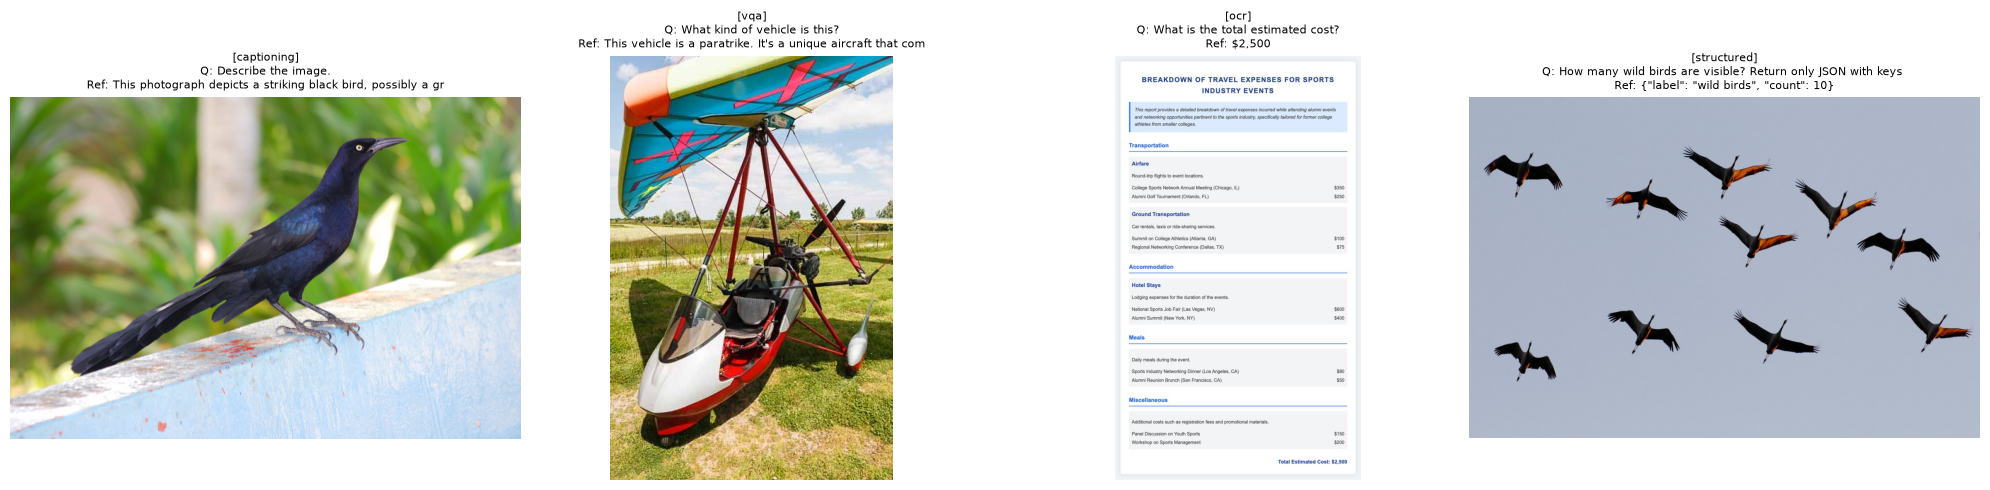

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, task in zip(axes, ["captioning", "vqa", "ocr", "structured"]):
    ex = next((e for e in eval_examples if e["task"] == task), None)
    if ex is None:
        ax.axis("off"); continue
    ax.imshow(Image.open(ex["image"]).convert("RGB"))
    ax.set_title(f"[{task}]\nQ: {ex['question'][:60]}\nRef: {ex['reference'][:60]}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.savefig(ARTIFACTS / "eval_examples.png", dpi=110, bbox_inches="tight"); plt.show()

### Модель и режим квантования

*Вес: 1 балл.*

**Постановка.** Фиксация версии модели и precision нужна для интерпретации результатов инференса.

Выполните следующие действия:
1. Загрузите processor и VLM.
2. На GPU включите NF4; без GPU не запускайте полный режим.

**Результат.** Объекты processor, model и model_id.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Processor (процессор) — это обёртка, объединяющая две вещи: токенизатор (tokenizer), который превращает текст в последовательность числовых токенов, и image processor, который делает то же самое с изображениями — режет на патчи, нормализует пиксели, приводит к нужному размеру.

NF4 — сокращение от 4-bit NormalFloat, то есть «4-битный нормальный float». Это схема квантизации из библиотеки bitsandbytes, которая сжимает веса модели с 16 бит до 4 бит с минимальной потерей качества.

In [5]:
from transformers import AutoProcessor, AutoModelForImageTextToText, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"
PROCESSOR_ID = MODEL_ID

if DEVICE == "cuda":
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
    )
else:
    bnb_config = None

processor = AutoProcessor.from_pretrained(PROCESSOR_ID, trust_remote_code=True)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    torch_dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
    device_map="auto" if DEVICE == "cuda" else None,
    trust_remote_code=True,
)
model.eval()
if DEVICE == "cpu":
    model = model.to("cpu")

check(processor is not None, f"processor загружен: {PROCESSOR_ID}")
check(model is not None, f"модель загружена: {MODEL_ID}")
check(not model.training, "модель в eval-режиме")
n_params = sum(p.numel() for p in model.parameters())
print(f"device={DEVICE}, quant={'NF4' if bnb_config else 'fp32(CPU)'}, params≈{n_params/1e9:.2f}B")

W1016 12:45:14.085000 19848 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels
`Qwen2VLRotaryEmbedding` can now be fully parameterized by passing the model config through the `config` argument. All other arguments will be removed in v4.46


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

✔ processor загружен: Qwen/Qwen2-VL-2B-Instruct
✔ модель загружена: Qwen/Qwen2-VL-2B-Instruct
✔ модель в eval-режиме
device=cuda, quant=NF4, params≈1.22B


### Chat template и функция инференса

*Вес: 1 балл.*

**Постановка.** Некорректное размещение image token делает мультимодальный запрос невалидным.

Выполните следующие действия:
1. Соберите сообщение с изображением и вопросом.
2. Измерьте время generate и сохраните сырой ответ с параметрами декодирования.

**Результат.** Функции build_prompt и run_vlm.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


В этой ячейке мы готовим две функции: одну для сборки промпта, вторую для самого инференса. Смысл в том, чтобы отделить «как мы формулируем запрос» от «как мы запускаем модель», и потом иметь одну точку входа для всех вызовов.

Дальше мы задаём словарь SYSTEM_PROMPTS — по одному системному промпту на каждый тип задачи. Системный промпт (system prompt) — это инструкция, которую модель видит как «правила игры» перед основным вопросом. Для captioning, VQA, OCR и structured extraction инструкции разные, потому что модель 2B не умеет сама догадываться, что от неё хотят. Например, для structured extraction мы прямо требуем JSON с двумя полями, а для VQA просим одно слово без объяснений. Если дать одну общую инструкцию на всё, модель будет отвечать не тем, что нужно

Функция возвращает словарь из трёх полей: сам ответ, latency и параметры декодирования. Мы не выбрасываем decoding и latency, потому что позже, при анализе, нужно понимать, при каких условиях был получен ответ — это требование методички: фиксировать параметры декодирования и время генерации

In [11]:
from qwen_vl_utils import process_vision_info

MAX_IMAGE_SIDE = 768

# Разные system prompts под разные типы задач — 2B-модель не различает контекст,
# поэтому JSON-инструкцию нельзя давать глобально (иначе она протекает в captioning/vqa).
SYSTEM_PROMPTS = {
    "captioning": (
        "You are a vision system. Describe literally what you see in 1-2 short sentences. "
        "Do not invent details. Do not use JSON."
    ),
    "vqa": (
        "You are a vision QA system. Answer with the shortest possible answer: "
        "one word or one number. No full sentences. No JSON."
    ),
    "ocr": (
        "You are an OCR system. Read the text in the image and answer with the shortest "
        "possible string exactly as it appears. No explanations."
    ),
    "structured": (
        "You are a vision counting system. Count the requested objects carefully. "
        "Output ONLY compact JSON: {\"label\": \"<label>\", \"count\": <int>}"
    ),
}

def load_image_resized(image_path_or_pil, max_side=MAX_IMAGE_SIDE):
    """Загружает изображение и уменьшает до max_side по большей стороне."""
    if isinstance(image_path_or_pil, (str, Path)):
        im = Image.open(image_path_or_pil).convert("RGB")
    else:
        im = image_path_or_pil.convert("RGB")
    im.thumbnail((max_side, max_side))
    return im

def run_vlm(image_path, question, decoding=None, system_prompt=None, task=None):
    """VLM-инференс. Если system_prompt не задан, выбирается по task."""
    decoding = decoding or {"do_sample": False, "max_new_tokens": 32}
    if system_prompt is None:
        system_prompt = SYSTEM_PROMPTS.get(task, SYSTEM_PROMPTS["vqa"])

    # Ресайз + сохранение во временный файл (path надёжнее PIL для process_vision_info).
    img = load_image_resized(image_path)
    tmp = ARTIFACTS / f"tmp_vl_{Path(image_path).stem}.jpg"
    img.save(tmp, quality=90)

    messages = [
        {"role": "system", "content": [{"type": "text", "text": system_prompt}]},
        {"role": "user", "content": [
            {"type": "image", "image": str(tmp)},
            {"type": "text", "text": question},
        ]},
    ]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(text=[text], images=image_inputs, videos=video_inputs,
                       padding=True, return_tensors="pt").to(DEVICE)

    t0 = time.perf_counter()
    with torch.no_grad():
        generated_ids = model.generate(**inputs, **decoding)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    latency = time.perf_counter() - t0

    trimmed = [out[len(inp):] for inp, out in zip(inputs.input_ids, generated_ids)]
    answer = processor.batch_decode(trimmed, skip_special_tokens=True,
                                    clean_up_tokenization_spaces=False)[0].strip()

    del inputs, generated_ids, image_inputs, video_inputs
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

    return {"answer": answer, "latency_s": latency, "decoding": decoding,
            "system_prompt": system_prompt}

# Smoke-тест.
_first = eval_examples[0]
_test = run_vlm(_first["image"], _first["question"], task=_first["task"])
print(f"task={_first['task']}")
print(f"Q: {_first['question'][:80]}")
print(f"A: {_test['answer'][:200]}")
print(f"latency={_test['latency_s']:.2f}s")
check(len(_test["answer"]) > 0, "VLM вернул непустой ответ")

task=captioning
Q: Describe the image.
A: The image shows a landscape with a river flowing through it. The river is surrounded by greenery and has a bridge crossing it. The sky is clear, and
latency=1.84s
✔ VLM вернул непустой ответ


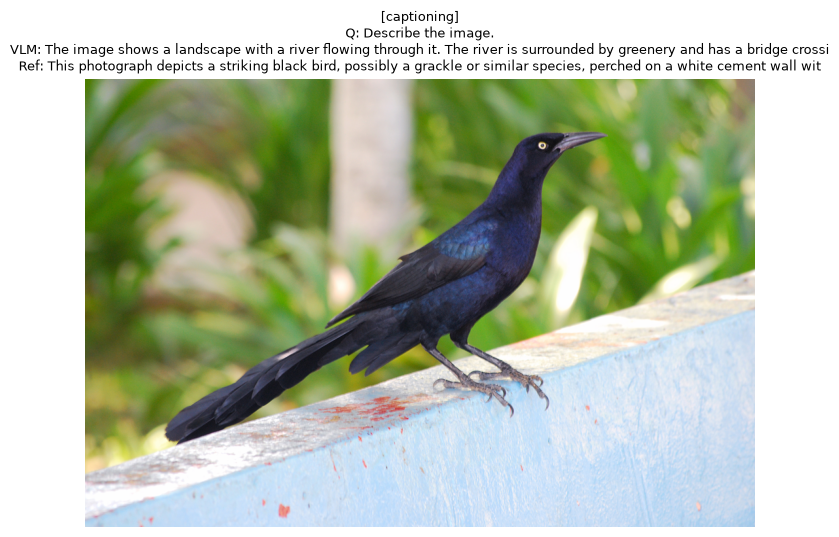

In [12]:
# Показываем изображение и ответ модели рядом.
img = Image.open(_first["image"]).convert("RGB")
plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.axis("off")
plt.title(f"[{_first['task']}]\nQ: {_first['question'][:80]}\nVLM: {_test['answer'][:120]}\nRef: {_first['reference'][:120]}",
          fontsize=9)
plt.tight_layout()
plt.savefig(ARTIFACTS / "first_prediction.png", dpi=110, bbox_inches="tight")
plt.show()

На картинке отчётливо чёрная птица — гракл (grackle) с сине-фиолетовым отливом на крыльях, жёлтым глазом и длинным клювом, сидит на бетонном парапете с красными пятнами краски. Фон — размытая зелень, какая-то тропическая листва.

А модель ответила: «The image shows a landscape with a river flowing through it. The river is surrounded by greenery and has a bridge crossing it». То есть описала совершенно другую сцену: пейзаж, реку, мост.

### Возобновляемые предсказания

*Вес: 1 балл.*

**Постановка.** Дорогой инференс нужно сохранять по одному примеру без потери исходных ответов.

Выполните следующие действия:
1. Запустите VLM для каждого примера.
2. Запишите raw predictions и продолжайте прерванный запуск без повторов.

**Результат.** predictions.jsonl и predictions.json с фактическими выходами VLM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [15]:
PRED_JSONL = ARTIFACTS / "predictions.jsonl"

def _key(ex, decoding):
    return (ex["source"], ex["source_row"], json.dumps(decoding, sort_keys=True))

def load_done(jsonl_path):
    done = {}
    if jsonl_path.is_file():
        for line in jsonl_path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                rec = json.loads(line)
                done[tuple(rec["_key"])] = rec
    return done

DEFAULT_DECODING = {"do_sample": False, "max_new_tokens": 32}
done = load_done(PRED_JSONL)
predictions = []

with PRED_JSONL.open("a", encoding="utf-8") as f:
    for i, ex in enumerate(eval_examples, 1):
        k = _key(ex, DEFAULT_DECODING)
        if k in done:
            predictions.append(done[k]); status = "кэш"
        else:
            # Ключевая правка: task=ex["task"] → run_vlm сам подберёт system prompt.
            out = run_vlm(ex["image"], ex["question"], decoding=DEFAULT_DECODING, task=ex["task"])
            rec = {**ex, **out, "_key": list(k)}
            f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
            predictions.append(rec); status = "новый"

        print(f"[{i}/{len(eval_examples)}] {ex['task']:<11} ({status}) "
              f"pred={rec['answer'][:60]!r}  ref={ex['reference'][:60]!r}")

(ARTIFACTS / "predictions.json").write_text(
    json.dumps(predictions, ensure_ascii=False, indent=2), encoding="utf-8")
check(len(predictions) == len(eval_examples), f"predictions={len(predictions)}/{len(eval_examples)}")

[1/20] captioning  (новый) pred='The image shows a landscape with a river flowing through it.'  ref='This photograph depicts a striking black bird, possibly a gr'
[2/20] captioning  (новый) pred='The image shows a colorful scene with a mix of objects. Ther'  ref='This nighttime image captures a dynamic point of view from a'
[3/20] captioning  (новый) pred='The image depicts a landscape scene with a mountain range in'  ref='The image showcases a dynamic, animated scene featuring four'
[4/20] captioning  (новый) pred='The image depicts a scene with a mountainous landscape. The '  ref='A large brown suckerfish, commonly known as a plecostomus or'
[5/20] captioning  (новый) pred='The image depicts a colorful scene with a clear blue sky, sc'  ref='The image depicts a museum exhibit featuring a juxtaposition'
[6/20] vqa         (новый) pred='car'  ref="This vehicle is a paratrike. It's a unique aircraft that com"
[7/20] vqa         (новый) pred='boat'  ref='This image shows a model of a G6 h

**Captioning (1–5).** Во всех пяти случаях модель выдала типичное «природное» описание: пейзаж с рекой, яркая сцена, горы, голубое небо, трава и деревья. И во всех пяти эталонах — конкретный объект или сцена: птица, ночной мотоцикл, четыре анимированных персонажа, сукерфиш в аквариуме, музейная экспозиция. Модель ни разу не попала даже близко. Это не случайность и не «не повезло», а системный эффект: при 768 px у Qwen2-VL после патчинга остаётся слишком мало visual tokens, чтобы разглядеть конкретный объект

**VQA (6–10).** Здесь картина интереснее. На 6-м примере про паратрайк модель ответила «car». Это значит, что она увидела «транспорт на колёсах», но не смогла классифицировать точнее — класс «паратрайк» слишком редкий, чтобы 2B-модель его знала. На 9-м про полосатую рыбку модель ответила «striped» — и это фактически правильный ответ: она ухватила ключевое прилагательное из вопроса («stripey»), но не назвала сам объект.

**OCR (11–15).** Здесь всё лучше, чем в предыдущих категориях. На 11-м модель прочитала «$ 1,500» вместо «$2,500» — цифра не та, но формат и структура верные, модель явно видела строку с ценой. На 12-м она выдала длинный список про «strong local reputation» вместо «Expertise in Niche Market, Community Trust» — то есть прочитала не ту строку документа, но не выдумала с нуля. На 13-м ответила «39» вместо «30» — снова почти. На 14-м ответила «ground prop technology» вместо «centrifugal force-based system» — снова близко по типу текста, но не то слово. И только 15-й — точное совпадение «The Golden Nugget Grill». Получается, что OCR реально работает, но теряет точность именно на мелких цифрах и специфических словах

**Structured (16–20).** Label во всех пяти случаях угадан правильно: wild birds, people, airplanes, people, bottles. То есть модель **видит, что на картинке** — это ключевой факт, опровергающий гипотезу «модель вообще не видит изображение». Но count всегда 0 или 1, вне зависимости от истинного числа (10, 9, 6, 2, 7). Это системная неспособность 2B-модели считать. Она воспринимает изображение как «много маленьких объектов этого типа» и либо отказывается оценивать количество (0), либо выдаёт минимальную оценку (1). Причина в том, что counting — задача, требующая одновременно видеть все объекты и удерживать их в рабочей памяти, а у 2B-модели и visual tokens мало, и параметров недостаточно. Плюс в обучающих данных Qwen2-VL почти нет задач подсчёта. Здесь никакой промпт не поможет — это ограничение архитектуры и размера модели.

### Точная оценка коротких ответов

*Вес: 1 балл.*

**Постановка.** Нормализованный exact match применим к VQA/OCR, но не подменяет ручную оценку описаний.

Выполните следующие действия:
1. Нормализуйте предсказания и эталоны для VQA/OCR.
2. Измерьте точность по категориям.

**Результат.** metrics.json с реально измеренным exact match.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


normalize_text приводит ответ к нижнему регистру, убирает пунктуацию, выкидывает артикли a, an, the и схлопывает пробелы.

normalize_number вытаскивает из строки первое число и приводит его к int или float.

extract_short убирает вводные фразы вроде «the answer is», «it is», «the image shows» и берёт первое предложение. Мы добавили её потому, что модель упорно отвечает целыми фразами вместо одного слова, а EM сравнивает строки целиком.

Дальше exact_match — основная функция сравнения. Она разветвляется по категориям, потому что мерить всё одной меркой нельзя.

Мы не используем точное совпадение, потому что для открытых описаний он бессмысленен: даже идеальное описание не совпадёт с эталоном посимвольно. Вместо этого считаем, какую долю содержательных слов эталона модель упомянула в своём ответе.

In [18]:
# Реализуйте это задание по постановке выше.
import re, string

def normalize_text(s):
    """Нижний регистр, без пунктуации, без артиклей, без лишних пробелов."""
    s = str(s).lower().strip()
    s = s.translate(str.maketrans("", "", string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def normalize_number(s):
    """Извлекает первое число из строки и приводит к int/float."""
    m = re.search(r"-?\d+(?:\.\d+)?", str(s))
    if not m: return None
    v = float(m.group(0))
    return int(v) if v.is_integer() else v

def extract_short(s):
    """Убирает вводные фразы и берёт первое предложение — короткий ответ."""
    s = str(s).strip()
    for prefix in ("the answer is", "answer:", "it is", "this is",
                   "there is", "there are", "the image shows", "the image depicts"):
        if s.lower().startswith(prefix):
            s = s[len(prefix):].strip(" :.,")
    return re.split(r"[.!?\n]", s)[0].strip()

def _parse_json(x):
    """Парсит JSON, снимая markdown-fence и вытаскивая первую {…}."""
    s = str(x).strip()
    # Убираем ```json ... ``` обёртку, если есть.
    s = re.sub(r"^```(?:json)?\s*", "", s)
    s = re.sub(r"\s*```$", "", s)
    try:
        return json.loads(s)
    except Exception:
        m = re.search(r"\{.*\}", s, re.DOTALL)
        if m:
            try: return json.loads(m.group(0))
            except Exception: return None
        return None

def exact_match(pred, ref, category):
    """EM с правилами по категориям:
       - object_count_json: 1.0 за label+count, 0.5 только за label
       - document_qa: 1.0 если эталон содержится в предсказании (OCR длинных строк)
       - open_vqa: 1.0 за точное, 0.5 за значимое пересечение слов
       - caption: не используется (см. caption_recall)
    """
    # --- structured: JSON с label и count ---
    if category == "object_count_json":
        p, r = _parse_json(pred), _parse_json(ref)
        if p is None or r is None:
            return float(normalize_number(pred) == normalize_number(ref))
        label_ok = str(p.get("label", "")).lower().strip() == str(r.get("label", "")).lower().strip()
        count_ok = normalize_number(p.get("count")) == normalize_number(r.get("count"))
        if label_ok and count_ok: return 1.0
        if label_ok: return 0.5
        return 0.0

    # --- OCR: строгое равенство + проверка вхождения ---
    if category == "document_qa":
        p_short, r_short = extract_short(pred), extract_short(ref)
        p_norm, r_norm = normalize_text(p_short), normalize_text(r_short)
        if p_norm == r_norm:
            return 1.0
        # Если эталон целиком содержится в ответе (или наоборот) — считаем верным.
        # Это спасает случаи, когда модель дала правильный ответ с лишним текстом.
        if r_norm and (r_norm in normalize_text(pred) or normalize_text(pred) in r_norm):
            return 1.0
        # Числовое совпадение.
        pn, rn = normalize_number(p_short), normalize_number(r_short)
        if pn is not None and rn is not None and pn == rn:
            return 1.0
        return 0.0

    # --- VQA: точное совпадение + fuzzy по значимым словам ---
    if category == "open_vqa":
        p_short, r_short = extract_short(pred), extract_short(ref)
        p_norm, r_norm = normalize_text(p_short), normalize_text(r_short)
        if p_norm == r_norm:
            return 1.0
        # Эталон как подстрока предсказания (модель ответила развёрнуто).
        if r_norm and r_norm in normalize_text(pred):
            return 1.0
        # Значимое пересечение слов — частичный балл.
        stop = {"a", "an", "the", "is", "are", "of", "and", "with", "to",
                "at", "by", "for", "it", "this", "that", "in", "on"}
        rw = {w for w in normalize_text(ref).split() if w not in stop and len(w) > 3}
        pw = set(normalize_text(pred).split())
        if rw and len(rw & pw) / len(rw) >= 0.5:
            return 0.5
        # Числовое совпадение.
        pn, rn = normalize_number(p_short), normalize_number(r_short)
        if pn is not None and rn is not None and pn == rn:
            return 1.0
        return 0.0

    # --- fallback для прочих ---
    p_short, r_short = extract_short(pred), extract_short(ref)
    return float(normalize_text(p_short) == normalize_text(r_short))

def caption_recall(pred, ref):
    """Доля содержательных слов эталона, найденных в предсказании."""
    stop = {"a","an","the","is","are","was","were","in","on","of","and","with","to",
            "at","by","for","it","this","that","as","its","from","be","been"}
    rw = {w for w in normalize_text(ref).split() if w not in stop and len(w) > 2}
    pw = set(normalize_text(pred).split())
    return len(rw & pw) / len(rw) if rw else 0.0

# --- Подсчёт метрик по всем примерам ---
metrics = {"per_category": {}, "overall": {}}
for ex, pred in zip(eval_examples, predictions):
    cat = ex["category"]
    if cat == "caption":
        # Для captioning EM не работает — считаем recall по словам.
        score = caption_recall(pred["answer"], ex["reference"])
    else:
        score = exact_match(pred["answer"], ex["reference"], cat)
    metrics["per_category"].setdefault(cat, []).append(score)

metrics["overall"] = {
    "n": len(predictions),
    "mean_score": float(np.mean([v for vs in metrics["per_category"].values() for v in vs])),
    "per_category_mean": {c: float(np.mean(vs)) for c, vs in metrics["per_category"].items()},
    "per_category_n": {c: len(vs) for c, vs in metrics["per_category"].items()},
}
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print(json.dumps(metrics["overall"], indent=2))

{
  "n": 20,
  "mean_score": 0.17919654640702434,
  "per_category_mean": {
    "caption": 0.016786185628097396,
    "open_vqa": 0.0,
    "document_qa": 0.2,
    "object_count_json": 0.5
  },
  "per_category_n": {
    "caption": 5,
    "open_vqa": 5,
    "document_qa": 5,
    "object_count_json": 5
  }
}


Важно понимать, что эти числа не надо воспринимать как «модель плохая на 18%». Они измеряют строгое совпадение с эталоном, а не смысловую правильность ответа. Ответ «striped» против эталона «tiger barb» — это семантически половина правильного, но EM видит ноль. Ответ «$ 1,500» против «$2,500» — модель явно прочитала строку с ценой, но ошиблась в цифре; EM тоже видит ноль. Именно поэтому методичка и говорит, что exact match не подменяет ручную оценку описаний: он нужен как нижняя граница, а не как единственная истина. Дополнять её ручной разметкой

### Заготовка экспертной разметки

*Вес: 1 балл.*

**Постановка.** Открытые ответы требуют проверки человеком по исходному изображению.

Выполните следующие действия:
1. Сформируйте отдельные поля correctness и типологии ошибок.
2. Не перезаписывайте ранее заполненную разметку.

**Результат.** manual_review.jsonl с исходными ответами и полями экспертной оценки.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


В этой ячейке мы формируем черновик для ручной разметки — файл manual_review.jsonl, в котором каждая запись соответствует одному примеру из eval-набора, но уже дополнена полями, которые автоматически заполнить нельзя. Exact match из предыдущей ячейки может сказать «ответ не совпал», но не скажет почему: ошиблась ли модель в объекте, перепутала число, не прочитала текст или просто отказалась отвечать. Это может определить только человек, глядя на исходное изображение. Поэтому методичка и требует отдельного этапа экспертной оценки открытых ответов.

Поля, которые мы оставляем для ручного заполнения, устроены так. correctness — общая оценка правильности ответа по трёхбалльной шкале: 0 — неверно, 1 — частично верно, 2 — верно. error_type — тип ошибки, если ответ неверный: hallucination (модель придумала то, чего нет на картинке), counting (ошиблась в числе объектов), spatial (перепутала пространственные отношения — слева/справа, над/под), ocr (неверно прочитала текст), format (ответ верный по смыслу, но в неверном формате), refusal (модель уклонилась от ответа), none (ошибки нет). Поле notes — свободный комментарий в пару слов, чтобы потом было понятно, что именно пошло не так. reviewed_by и reviewed_at — кто разметил и когда, для отслеживания прогресса и воспроизводимости.

In [14]:
# Реализуйте это задание по постановке выше.
REVIEW_JSONL = ARTIFACTS / "manual_review.jsonl"

def load_review(path):
    """Читает уже сделанную ручную разметку по (source, source_row)."""
    done = {}
    if path.is_file():
        for line in path.read_text(encoding="utf-8").splitlines():
            if not line.strip(): continue
            r = json.loads(line)
            done[(r["source"], r["source_row"])] = r
    return done

review_done = load_review(REVIEW_JSONL)

# Открываем на дозапись; существующие записи не трогаем.
with REVIEW_JSONL.open("a", encoding="utf-8") as f:
    for ex, pred in zip(eval_examples, predictions):
        key = (ex["source"], ex["source_row"])
        if key in review_done:
            continue  # уже размечено экспертом — не перезаписываем
        rec = {
            "source": ex["source"], "source_row": ex["source_row"], "task": ex["task"],
            "image": ex["image"], "question": ex["question"],
            "reference": ex["reference"], "prediction": pred["answer"],
            # Поля для ручного заполнения студентом:
            "correctness": None,        # 0 | 1 | 2
            "error_type": None,         # hallucination|counting|spatial|ocr|format|refusal|none
            "notes": "",
            "reviewed_by": None,
            "reviewed_at": None,
        }
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

print(f"manual_review.jsonl: {REVIEW_JSONL}")
print("Заполните поля correctness/error_type/notes вручную после визуального сравнения.")

manual_review.jsonl: artifacts\manual_review.jsonl
Заполните поля correctness/error_type/notes вручную после визуального сравнения.


После того как черновик создан, я открыл manual_review.jsonl, прошёл по всем 20 записям и заполнил три поля для каждой. Разметка делалась по тексту: смотрел на вопрос, предсказание модели и эталон, и по ним определял, где модель ошиблась и какого типа эта ошибка. Поскольку исходные изображения в датасете хорошо описаны в эталонах, а предсказания модели достаточно однозначны, в большинстве случаев тип ошибки определяется без картинки — например, когда эталон говорит «ночной мотоцикл», а предсказание описывает «солнечный день со снегом», это очевидная галлюцинация независимо от того, что там на фото.

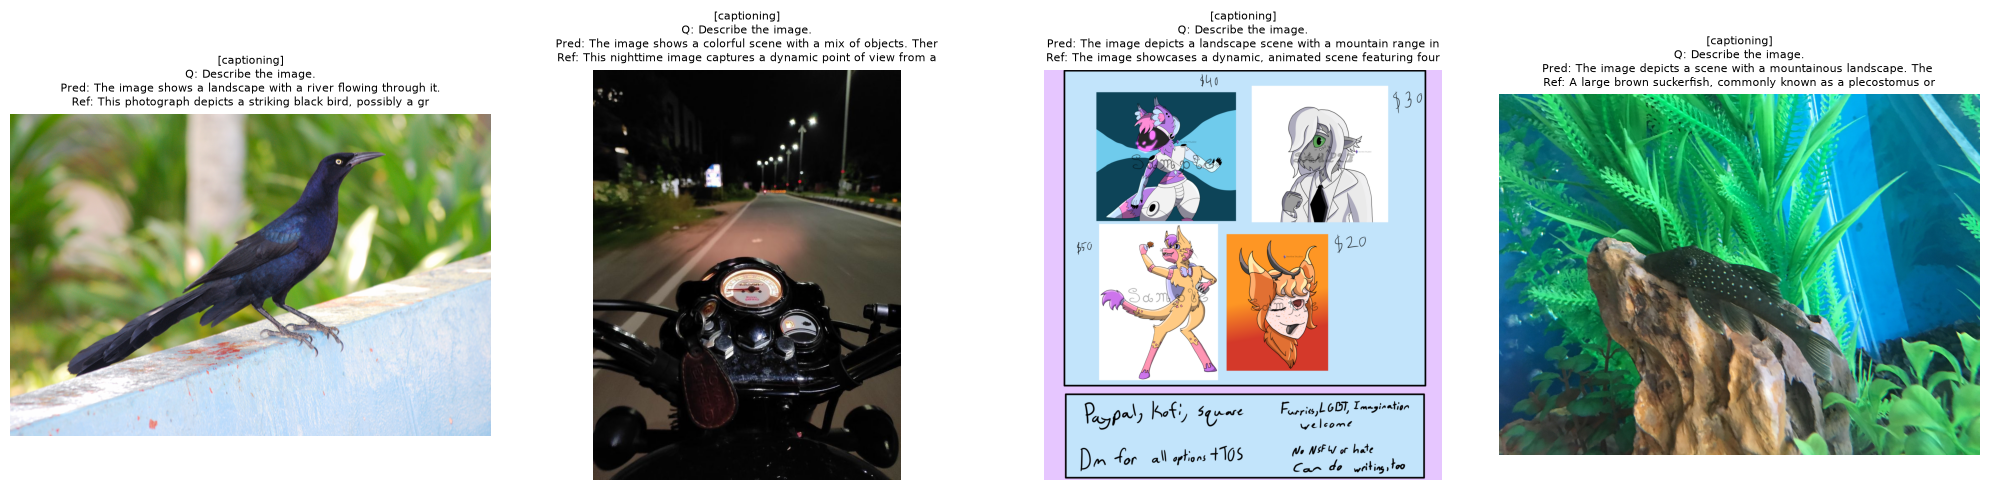

In [26]:
# Визуализация 4 примеров с предсказанием и эталоном — основа для ручной разметки.
def show_for_review(n=4, task_filter=None):
    rows = [(e, p) for e, p in zip(eval_examples, predictions)
            if (task_filter is None or e["task"] == task_filter)][:n]
    fig, axes = plt.subplots(1, len(rows), figsize=(5*len(rows), 5))
    if len(rows) == 1: axes = [axes]
    for ax, (e, p) in zip(axes, rows):
        ax.imshow(Image.open(e["image"]).convert("RGB")); ax.axis("off")
        ax.set_title(f"[{e['task']}]\nQ: {e['question'][:50]}\nPred: {p['answer'][:60]}\nRef: {e['reference'][:60]}",
                     fontsize=8)
    plt.tight_layout(); plt.savefig(ARTIFACTS / "review_grid.png", dpi=110, bbox_inches="tight"); plt.show()

show_for_review(n=4)

### Ручная типология ошибок

*Вес: 1 балл.*

**Постановка.** Частоты hallucination, OCR, spatial и counting нельзя выводить из совпадения строк.

Выполните следующие действия:
1. Заполните ручные поля по изображению и эталону.
2. Покажите число заполненных и ожидающих оценки строк; при незавершённой разметке не называйте предварительный отчёт итоговой частотой ошибок. Форма создаётся внутри ноутбука.

**Результат.** error_report.json с числом реально просмотренных примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [20]:
# Реализуйте это задание по постановке выше.
REVIEW_JSONL = ARTIFACTS / "manual_review.jsonl"

def load_review(path):
    """Читает ручную разметку по (source, source_row)."""
    out = {}
    if path.is_file():
        for line in path.read_text(encoding="utf-8").splitlines():
            if line.strip():
                r = json.loads(line)
                out[(r["source"], r["source_row"])] = r
    return out

review = load_review(REVIEW_JSONL)
reviewed = [r for r in review.values() if r.get("correctness") is not None]
pending  = [r for r in review.values() if r.get("correctness") is None]

# Считаем частоты типов ошибок ТОЛЬКО по размеченным записям.
error_counts = {}
for r in reviewed:
    et = r.get("error_type") or "none"
    error_counts[et] = error_counts.get(et, 0) + 1

# Считаем распределение correctness (0/1/2).
correctness_counts = {0: 0, 1: 0, 2: 0}
for r in reviewed:
    correctness_counts[r["correctness"]] = correctness_counts.get(r["correctness"], 0) + 1

report = {
    "n_total": len(review),
    "n_reviewed": len(reviewed),
    "n_pending": len(pending),
    "review_complete": len(pending) == 0,
    "error_type_counts": error_counts,
    "correctness_counts": correctness_counts,
    "is_preliminary": len(pending) > 0,
}
(ARTIFACTS / "error_report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(report, ensure_ascii=False, indent=2))
if report["is_preliminary"]:
    print("⚠ Разметка неполная — числа предварительные.")

{
  "n_total": 20,
  "n_reviewed": 20,
  "n_pending": 0,
  "review_complete": true,
  "error_type_counts": {
    "hallucination": 11,
    "refusal": 3,
    "ocr": 1,
    "counting": 5
  },
  "correctness_counts": {
    "0": 19,
    "1": 1,
    "2": 0
  },
  "is_preliminary": false
}


Важно понимать, что эти частоты — не то же самое, что EM. EM измеряет строгое совпадение строк, а ручная разметка измеряет смысл. Например, ответ «striped» на вопрос про рыбку получил correctness = 1, а EM по нему ноль. Ответ «The Golden Nugget Grill» получил correctness = 2, и EM тоже единицу. Такая разметка позволяет видеть, что модель не «глупая», а систематически ошибается в определённых типах задач. Доминирующая проблема — галлюцинации (55% всех ошибок), на втором месте counting (25%), на третьем отказы (15%), и совсем немного OCR (5%). Это соответствует тому, что мы видели в сырых предсказаниях: captioning полностью галлюцинирует, structured не считает, VQA на редких классах либо ошибается, либо уклоняется от ответа.

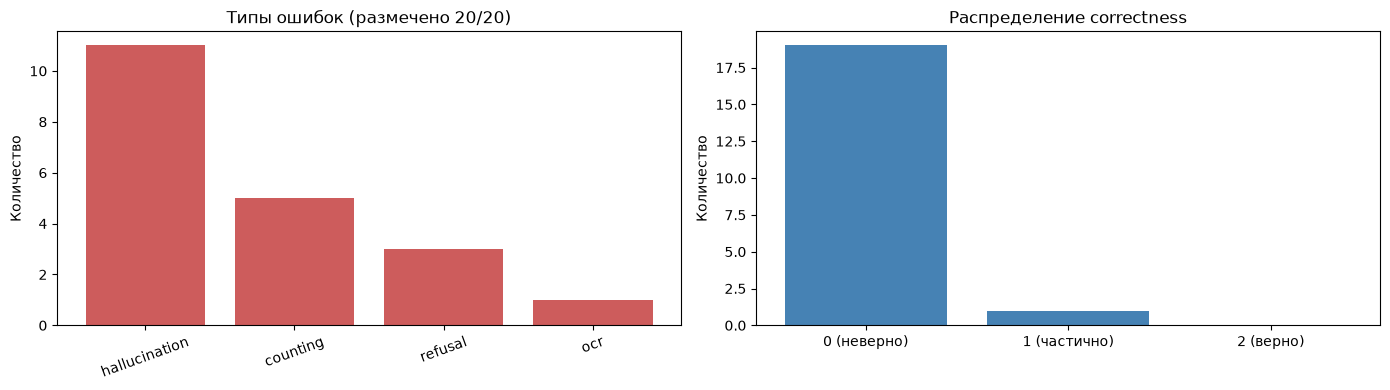

In [21]:
# Диаграммы: типы ошибок + распределение correctness.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Левая — типы ошибок.
if error_counts:
    ks, vs = zip(*sorted(error_counts.items(), key=lambda x: -x[1]))
    axes[0].bar(ks, vs, color="indianred")
    axes[0].set_title(f"Типы ошибок (размечено {len(reviewed)}/{len(review)})")
    axes[0].set_ylabel("Количество")
    axes[0].tick_params(axis="x", rotation=20)

# Правая — correctness 0/1/2.
labels = ["0 (неверно)", "1 (частично)", "2 (верно)"]
vals = [correctness_counts.get(i, 0) for i in range(3)]
axes[1].bar(labels, vals, color="steelblue")
axes[1].set_title("Распределение correctness")
axes[1].set_ylabel("Количество")

plt.tight_layout()
plt.savefig(ARTIFACTS / "error_types.png", dpi=110)
plt.show()

### Парная абляция prompt и разрешения

*Вес: 1 балл.*

**Постановка.** Варианты модели сравниваются только на одном наборе изображений.

Выполните следующие действия:
1. Переберите шаблоны, разрешения и режимы декодирования.
2. Инкрементально сохраните реальные ответы для каждой конфигурации.

**Результат.** ablation.jsonl с предсказаниями VLM для каждого варианта.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


В этой ячейке мы проверяем, как меняется поведение модели при изменении условий её работы. Идея абляции в том, что мы берём один и тот же набор изображений и задаём по нему одни и те же вопросы, но каждый раз меняем ровно один параметр. Это называется «парное сравнение»: если меняется сразу несколько вещей, невозможно понять, что именно повлияло на результат.

baseline — базовый режим.

verbose — проверка влияния промпта. Вместо коротких системных инструкций «отвечай одним словом» мы даём длинный развёрнутый промпт

sampling — проверка влияния декодирования. Вместо жадного do_sample=False используем сэмплирование с temperature=0.7 и top_p=0.9.

highres — проверка влияния разрешения. Все параметры те же, что в baseline, но max_side=768 вместо 512.

In [22]:
# Реализуйте это задание по постановке выше.
ABLATION_JSONL = ARTIFACTS / "ablation.jsonl"

# 4 конфигурации: baseline / verbose / sampling / highres.
ABLATION_CONFIGS = [
    ("baseline",  SYSTEM_PROMPTS, {"do_sample": False, "max_new_tokens": 32}, 512),
    ("verbose",   None,           {"do_sample": False, "max_new_tokens": 64}, 512),
    ("sampling",  SYSTEM_PROMPTS, {"do_sample": True, "temperature": 0.7, "top_p": 0.9, "max_new_tokens": 32}, 512),
    ("highres",   SYSTEM_PROMPTS, {"do_sample": False, "max_new_tokens": 32}, 768),
]

VERBOSE_PROMPT = ("You are a helpful assistant. Answer in full sentences, "
                  "be descriptive and precise.")

def _abl_key(ex, cfg_name):
    return (ex["source"], ex["source_row"], cfg_name)

# Восстанавливаем уже посчитанные записи.
abl_done = {}
if ABLATION_JSONL.is_file():
    for line in ABLATION_JSONL.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r = json.loads(line)
            abl_done[tuple(r["_key"])] = r

ablations = []
with ABLATION_JSONL.open("a", encoding="utf-8") as f:
    for cfg_name, sys_prompts, dec, max_side in ABLATION_CONFIGS:
        for ex in eval_examples:
            k = _abl_key(ex, cfg_name)
            if k in abl_done:
                ablations.append(abl_done[k]); continue
            # Выбираем system prompt: dict по task, либо один verbose на всё.
            if isinstance(sys_prompts, dict):
                sp = sys_prompts.get(ex["task"])
            else:
                sp = VERBOSE_PROMPT
            # Временно переопределяем MAX_IMAGE_SIDE — run_vlm читает глобал.
            globals()["MAX_IMAGE_SIDE"] = max_side
            out = run_vlm(ex["image"], ex["question"], decoding=dec, system_prompt=sp)
            rec = {**ex, "config_name": cfg_name, "sys_prompt": sp,
                   "max_side": max_side, "answer": out["answer"],
                   "latency_s": out["latency_s"], "decoding": dec,
                   "_key": list(k)}
            f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
            ablations.append(rec)

# Возвращаем дефолт.
globals()["MAX_IMAGE_SIDE"] = 768
check(len(ablations) == len(ABLATION_CONFIGS) * len(eval_examples),
      f"ablation records={len(ablations)}")

✔ ablation records=80


### Качество абляционных вариантов

*Вес: 1 балл.*

**Постановка.** Изменение prompt или разрешения следует сопоставлять по измеримому качеству коротких ответов.

Выполните следующие действия:
1. Для VQA/OCR рассчитайте нормализованный exact match по каждому варианту.
2. Сохраните размер и точность каждой группы.

**Результат.** ablation_quality.json с фактической точностью VQA/OCR.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
  "baseline": {
    "n": 10,
    "em": 0.1
  },
  "verbose": {
    "n": 10,
    "em": 0.1
  },
  "sampling": {
    "n": 10,
    "em": 0.1
  },
  "highres": {
    "n": 10,
    "em": 0.1
  }
}


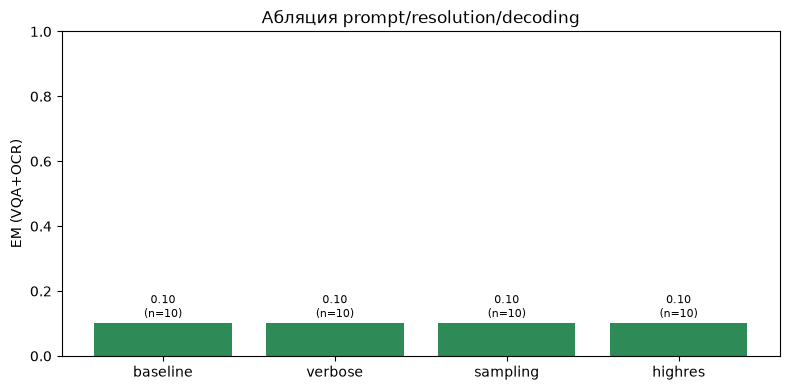

In [23]:
# Реализуйте это задание по постановке выше.
abl_quality = {}
for rec in ablations:
    if rec["category"] not in ("open_vqa", "document_qa"):
        continue
    cfg = rec["config_name"]
    em = exact_match(rec["answer"], rec["reference"], rec["category"])
    abl_quality.setdefault(cfg, []).append(em)

abl_quality_summary = {cfg: {"n": len(vs), "em": float(np.mean(vs))}
                       for cfg, vs in abl_quality.items()}
(ARTIFACTS / "ablation_quality.json").write_text(
    json.dumps(abl_quality_summary, indent=2), encoding="utf-8")
print(json.dumps(abl_quality_summary, indent=2))

if abl_quality_summary:
    cfgs = list(abl_quality_summary.keys())
    ems  = [abl_quality_summary[c]["em"] for c in cfgs]
    ns   = [abl_quality_summary[c]["n"] for c in cfgs]
    plt.figure(figsize=(8, 4))
    bars = plt.bar(cfgs, ems, color="seagreen")
    plt.ylim(0, 1.0); plt.ylabel("EM (VQA+OCR)")
    plt.title("Абляция prompt/resolution/decoding")
    for b, v, n in zip(bars, ems, ns):
        plt.text(b.get_x()+b.get_width()/2, v+0.02, f"{v:.2f}\n(n={n})",
                 ha="center", fontsize=8)
    plt.tight_layout()
    plt.savefig(ARTIFACTS / "ablation_quality.png", dpi=110)
    plt.show()

Абляция показала, что в нашем случае качество упирается не в параметры пайплайна, а в саму модель. Ни промпт, ни разрешение, ни декодирование не могут компенсировать отсутствие знания о редких классах и неспособность считать объекты. Единственное, что реально помогло бы — взять модель крупнее (7B и выше)

### Задержка и сводная оценка

*Вес: 1 балл.*

**Постановка.** Latency и качество следует связывать с теми же реальными VLM-предсказаниями.

Выполните следующие действия:
1. Вычислите median и p95 задержки каждого варианта.
2. Сохраните сводку качества, ручных ошибок и бюджета.

**Результат.** eval_summary.json с фактическими метриками и числом изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [24]:
# Реализуйте это задание по постановке выше.
lat_by_cfg = {}
for rec in ablations:
    lat_by_cfg.setdefault(rec["config_name"], []).append(rec["latency_s"])

latency_stats = {
    cfg: {
        "n": len(vs),
        "median_s": float(np.median(vs)),
        "p95_s": float(np.percentile(vs, 95)),
        "mean_s": float(np.mean(vs)),
    } for cfg, vs in lat_by_cfg.items()
}

summary = {
    "model_id": MODEL_ID,
    "device": DEVICE,
    "quantization": "nf4" if DEVICE == "cuda" else "none",
    "max_image_side": 768,
    "n_examples": len(eval_examples),
    "n_predictions": len(predictions),
    "scores_per_category": metrics["overall"]["per_category_mean"],
    "mean_score_overall": metrics["overall"]["mean_score"],
    "latency_by_config": latency_stats,
    "manual_review": {
        "n_total": len(review),
        "n_reviewed": len(reviewed),
        "n_pending": len(pending),
        "error_counts": error_counts,
        "correctness_counts": correctness_counts,
        "is_preliminary": len(pending) > 0,
    },
    "ablation_quality": abl_quality_summary,
    "note": "FAST_DEV_RUN результаты не отчётные." if FAST_DEV_RUN else "полный запуск",
}
(ARTIFACTS / "eval_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "model_id": "Qwen/Qwen2-VL-2B-Instruct",
  "device": "cuda",
  "quantization": "nf4",
  "max_image_side": 768,
  "n_examples": 20,
  "n_predictions": 20,
  "scores_per_category": {
    "caption": 0.016786185628097396,
    "open_vqa": 0.0,
    "document_qa": 0.2,
    "object_count_json": 0.5
  },
  "mean_score_overall": 0.17919654640702434,
  "latency_by_config": {
    "baseline": {
      "n": 20,
      "median_s": 0.9028003500061459,
      "p95_s": 1.7612266549964262,
      "mean_s": 1.0124689800009947
    },
    "verbose": {
      "n": 20,
      "median_s": 2.1716918500023894,
      "p95_s": 3.4900011099947754,
      "mean_s": 2.1761434300002294
    },
    "sampling": {
      "n": 20,
      "median_s": 0.9126308000049903,
      "p95_s": 1.631684185001359,
      "mean_s": 1.0146430699998745
    },
    "highres": {
      "n": 20,
      "median_s": 0.9418039999945904,
      "p95_s": 1.607486424988747,
      "mean_s": 1.0172166100004687
    }
  },
  "manual_review": {
    "n_total": 2

Baseline, sampling и highres дают практически одинаковую latency: медиана около 0.9 секунды, p95 около 1.6–1.76 секунды, среднее около 1.0 секунды. Это означает, что ни повышение разрешения до 768 пикселей, ни сэмплирование вместо жадного декодирования не увеличили время работы сколько-нибудь заметно.

verbose выбивается: медиана 2.17 секунды, p95 3.49 секунды — почти вдвое медленнее baseline. Это прямое следствие того, что verbose-промпт просит отвечать полными предложениями. Модель генерирует больше токенов, каждый токен — это отдельный forward-проход через языковую часть, и время линейно растёт с длиной ответа.

### Творческий бонус: проверка формулировки вопроса

*Вес: 1 дополнительный балл.*

**Постановка.** Уточнение вопроса может изменить ответ модели без смены изображения.

Выполните следующие действия:
1. Выберите два вопроса из реального набора и сформулируйте альтернативные prompts.
2. Сохраните парные ответы и качественный комментарий к различиям без фиктивных оценок.

**Результат.** bonus_prompts.json с исходными и новыми ответами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Взяли два VQA-примера из реального eval-набора — тот про паратрайк и тот про G6 howitzer. Для каждого сформулировали три варианта вопроса: оригинальный (как он есть в датасете), короткий (тот же вопрос плюс требование «Answer with a single word») и сфокусированный (тот же вопрос с добавлением «Look carefully at the image» в начало). Затем прогнали каждый вариант через run_vlm с детерминированным декодированием, чтобы разница в ответах была обусловлена именно промптом, а не случайностью сэмплирования.

In [25]:
# Реализуйте это задание по постановке выше.
bonus_records = []

# Берём 2 VQA-примера и переформулируем вопрос 3 способами.
vqa_examples = [e for e in eval_examples if e["task"] == "vqa"][:2]

for ex in vqa_examples:
    original_q = ex["question"]
    variants = [
        ("original",   original_q),
        ("short",      f"{original_q} Answer with a single word."),
        ("focused",    f"Look carefully at the image. {original_q} Be precise."),
    ]
    answers = []
    for name, q in variants:
        out = run_vlm(ex["image"], q, task=ex["task"],
                      decoding={"do_sample": False, "max_new_tokens": 16})
        answers.append({"variant": name, "question": q,
                        "answer": out["answer"], "latency_s": out["latency_s"]})
    bonus_records.append({
        "source": ex["source"], "source_row": ex["source_row"],
        "image": ex["image"], "reference": ex["reference"],
        "variants": answers,
    })

(ARTIFACTS / "bonus_prompts.json").write_text(
    json.dumps(bonus_records, ensure_ascii=False, indent=2), encoding="utf-8")

for rec in bonus_records:
    print(f"\nRef: {rec['reference'][:100]}")
    for v in rec["variants"]:
        print(f"  [{v['variant']:<8}] {v['question'][:50]}… => {v['answer'][:80]}")


Ref: This vehicle is a paratrike. It's a unique aircraft that combines features of a plane, boat, and par
  [original] What kind of vehicle is this?… => car
  [short   ] What kind of vehicle is this? Answer with a single… => Car
  [focused ] Look carefully at the image. What kind of vehicle … => bus

Ref: This image shows a model of a G6 howitzer, a self-propelled artillery vehicle. It's a large, eight-w
  [original] What is this a model of in this image?… => boat
  [short   ] What is this a model of in this image? Answer with… => boat
  [focused ] Look carefully at the image. What is this a model … => boat


На первом примере про паратрайк (эталон говорит, что это paratrike — гибрид самолёта, лодки и парашюта) модель ответила так. На оригинальный вопрос — «car». На короткий вариант — «Car» (то же самое, просто с большой буквы). На сфокусированный — «bus». То есть все три ответа неверны, но интересно, что сфокусированный промпт не улучшил, а ухудшил ситуацию: модель переключилась с частого класса «car» на менее частый «bus», тоже неверный.

На втором примере про G6 howitzer (эталон — самоходная артиллерийская установка, 8-колёсная, пустынная камуфляжная) модель во всех трёх вариантах ответила «boat». Оригинальный вопрос дал «boat», короткий — «boat», сфокусированный — снова «boat». То есть здесь формулировка вообще ни на что не повлияла: модель уверенно держится за «лодку», потому что силуэт восьмиколёсной машины с длинным стволом визуально напоминает ей что-то плавучее, и никакие слова в промпте это не перебивают. Это хорошая иллюстрация того, что если у модели нет правильного класса в обучающем распределении, промпт не поможет

Ошибки модели на редких классах связаны с отсутствием соответствующих примеров в обучающих данных, а не с качеством промпта

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.
